# OASIS INFOBYTE INTERNSHIP

## Task 1: Iris Flower Classification

### Introduction

The Iris Flower Classification project is a Machine Learning classification task that aims to predict the species of an Iris flower based on its physical measurements.

The model classifies flowers into three different species:
- Setosa
- Versicolor
- Virginica

The classification is performed using four features:
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

### Objective

The main objective of this project is to build and evaluate Machine Learning classification models that can accurately identify Iris flower species using Python.

### Technologies Used
- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

### Machine Learning Algorithms
1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree Classifier

In [1]:
print("Hello! My Iris Classification project has started.")

Hello! My Iris Classification project has started.


In [4]:
%pip install numpy pandas matplotlib seaborn scikit-learn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.29.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.8 MB 316.6 kB/s eta 0:00:33
   - ----------------------------------


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# Load the Iris dataset
iris = load_iris()

# Convert the dataset into a Pandas DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add the species names
df["species"] = [iris.target_names[i] for i in iris.target]

# Display the first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [9]:
# 1. Check the number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Check column names and data types
print("\nDataset Information:")
df.info()

# 3. Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Get statistical information
print("\nDescriptive Statistics:")
display(df.describe())

# 5. Count each flower species
print("\nSpecies Distribution:")
print(df["species"].value_counts())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Descriptive Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


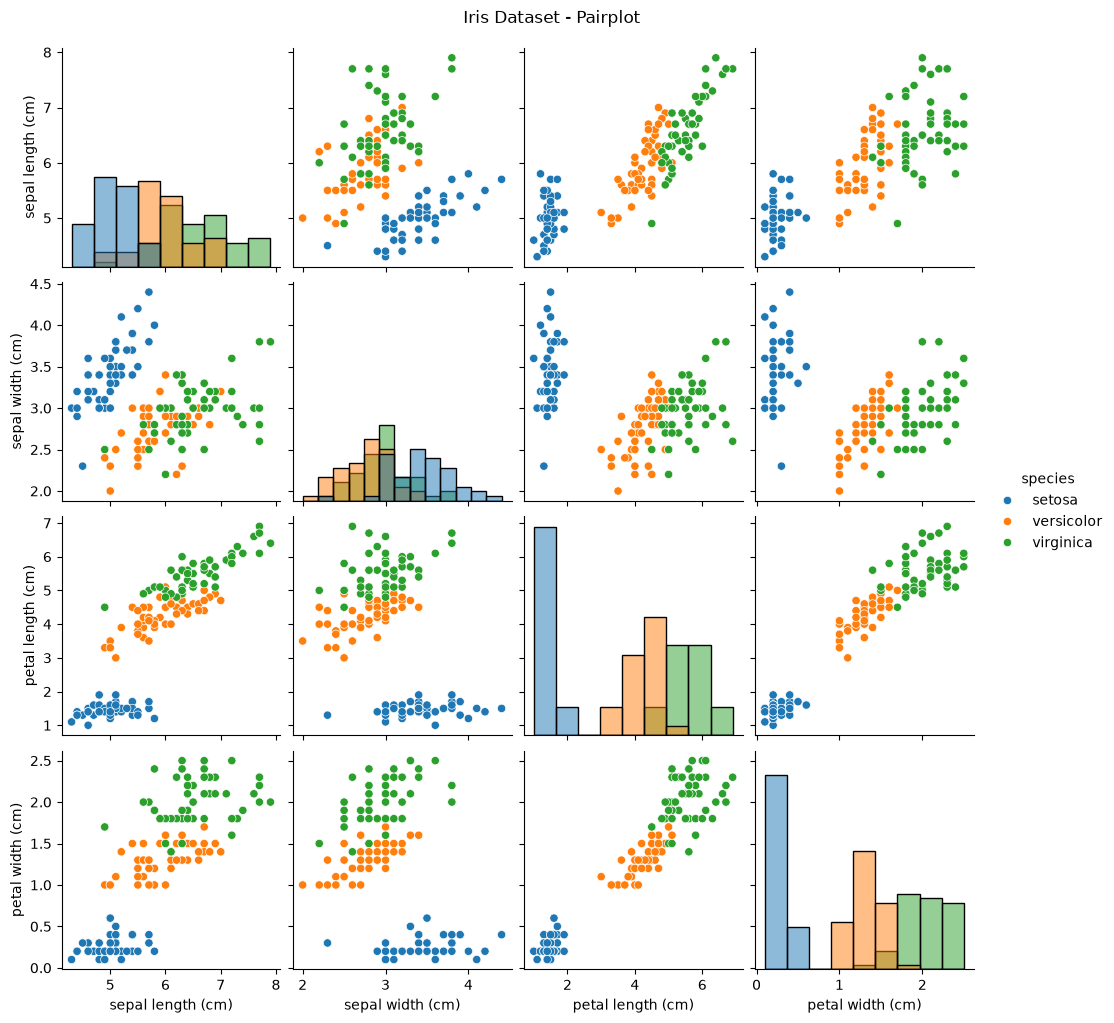

In [10]:
# Create a pairplot
sns.pairplot(df, hue="species", diag_kind="hist")

plt.suptitle("Iris Dataset - Pairplot", y=1.02)

plt.show()

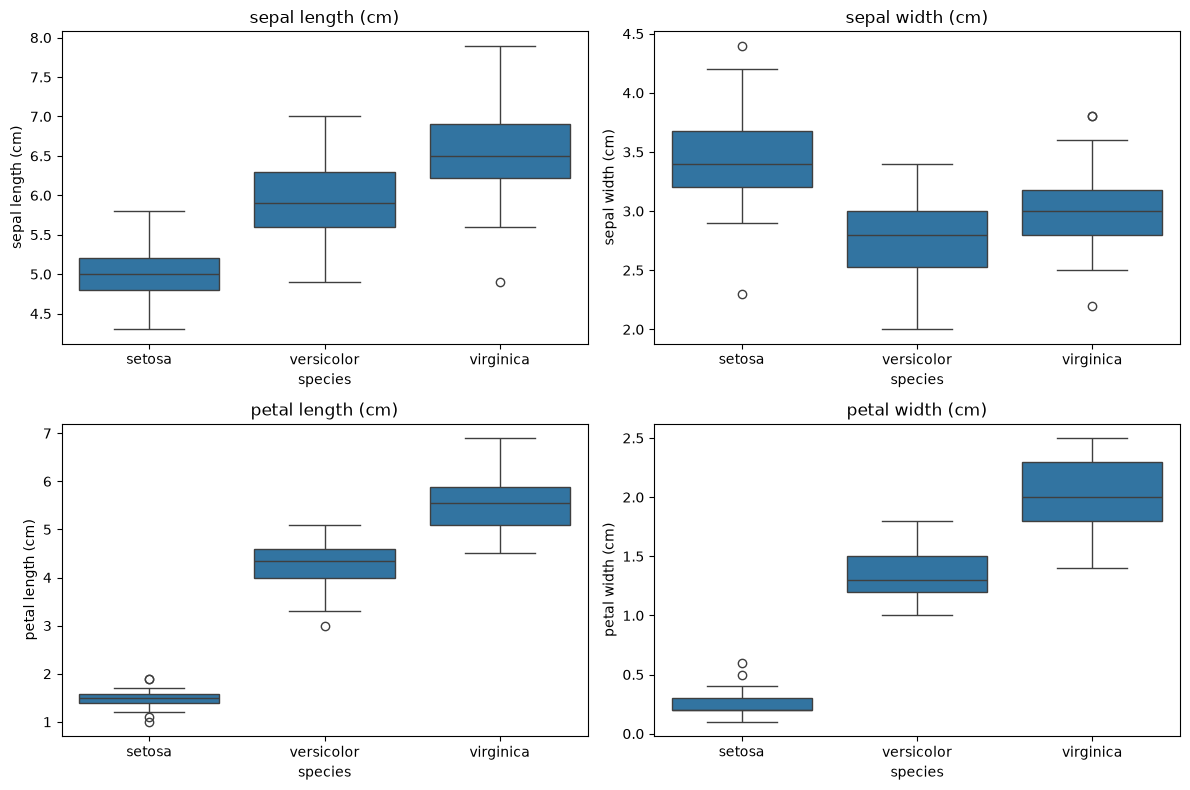

In [11]:
# Select the four measurement features
features = iris.feature_names

# Create a figure
plt.figure(figsize=(12, 8))

# Create a boxplot for each feature
for i, feature in enumerate(features):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(data=df, x="species", y=feature)
    plt.title(feature)

plt.tight_layout()
plt.show()

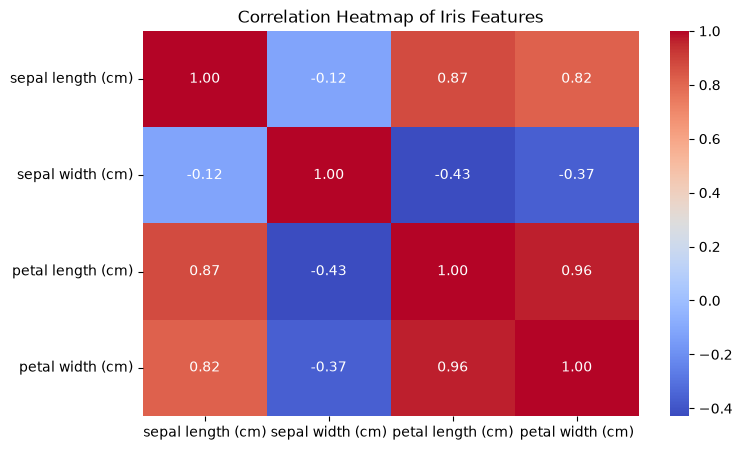

In [12]:
# Calculate correlation between numerical features
correlation = df[features].corr()

# Create a heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Iris Features")
plt.show()

In [13]:
# Select input features
X = df[features]

# Select target variable
y = iris.target

# Display the first five feature rows
print("Features (X):")
display(X.head())

# Display the first five target values
print("Target (y):")
print(y[:5])

Features (X):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Target (y):
[0 0 0 0 0]


In [14]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training targets: (120,)
Testing targets: (30,)


In [15]:
# Import required libraries
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create Logistic Regression model
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=200)
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [16]:
# Predict species using testing data
y_pred = logistic_model.predict(X_test)

print("Actual values:")
print(y_test)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [17]:
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


In [18]:
# Import KNN classifier
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [19]:
# Predict using KNN
knn_pred = knn_model.predict(X_test)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", knn_accuracy * 100, "%")

KNN Accuracy: 93.33333333333333 %


In [20]:
# Import Decision Tree classifier
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [21]:
# Predict using Decision Tree
dt_pred = dt_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


In [22]:
from sklearn.metrics import confusion_matrix, classification_report

# Store all models and predictions
models = {
    "Logistic Regression": (logistic_model, logistic_model.predict(X_test)),
    "KNN": (knn_model, knn_pred),
    "Decision Tree": (dt_model, dt_pred)
}

# Evaluate each model
for name, (model, predictions) in models.items():

    print("\nModel:", name)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=iris.target_names
    ))

    print("-" * 50)


Model: Logistic Regression

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

--------------------------------------------------

Model: KNN

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.9

In [23]:
print("KNN Classification Report:")
print(classification_report(
    y_test,
    knn_pred,
    target_names=iris.target_names
))

print("Decision Tree Classification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=iris.target_names
))

KNN Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Decision Tree Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [24]:
# Compare the accuracy of all three models

model_accuracies = {
    "Logistic Regression": accuracy,
    "KNN": knn_accuracy,
    "Decision Tree": dt_accuracy
}

for model_name, score in model_accuracies.items():
    print(f"{model_name}: {score * 100:.2f}%")

# Find the model with the highest accuracy
best_model = max(model_accuracies, key=model_accuracies.get)

print("\nBest Performing Model:", best_model)

Logistic Regression: 93.33%
KNN: 93.33%
Decision Tree: 93.33%

Best Performing Model: Logistic Regression


## Conclusion

In this project, I developed a Machine Learning Classification Model to predict the species of Iris flowers using Python.

The Iris dataset was loaded using Scikit-learn and explored using Pandas. Exploratory Data Analysis (EDA) was performed to understand the dataset, identify missing values, and examine the relationships between flower measurements.

Data visualization was performed using Matplotlib and Seaborn through pairplots, boxplots, and correlation heatmaps.

Three classification algorithms were implemented:
1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree Classifier

The dataset was divided into 80% training data and 20% testing data.

All three models achieved an accuracy of approximately **93.33%** on the test dataset. Their performance was evaluated using accuracy, confusion matrices, precision, recall, and F1-score.

The project demonstrates how Machine Learning can be used to classify Iris flowers into Setosa, Versicolor, and Virginica based on their physical measurements.